# Sky distribution of the Rubin detections by band
#### *Open Tools, Open Sky: Doing LSST Science with Public Rubin Data & LINCC Frameworks, UdeA, Medellín, October 13 2026*

Position (RA, Dec) of every Vera C. Rubin Observatory detection submitted to the Minor Planet Center, one Mollweide
map per filter (u, g, r, i, z, y). Each band has its own color, and the black line is the ecliptic. The MPC band codes `Lu, Lg, Lr, Li, Lz, Ly` (LSST filters) and the few plain `u, g, r, i` are merged.

In [ ]:
from util import *
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_dir = 'data/'
get_data(data_dir=data_dir, only=['obs_sbn_X05_full.parquet'])

In [ ]:
# Only the columns we need; ra, dec and mag are stored as strings
obs = pd.read_parquet(data_dir + 'obs_sbn_X05_full.parquet', columns=['ra', 'dec', 'mag', 'band'])
for col in ['ra', 'dec', 'mag']:
    obs[col] = pd.to_numeric(obs[col], errors='coerce')

# 'Lr' and 'r' -> 'r', etc.
obs['filter'] = obs['band'].str.replace('^L', '', regex=True)
obs = obs.dropna(subset=['ra', 'dec', 'mag', 'filter'])
print(f'{len(obs):,} detections with position, magnitude and band')
obs.groupby('filter')['mag'].describe()

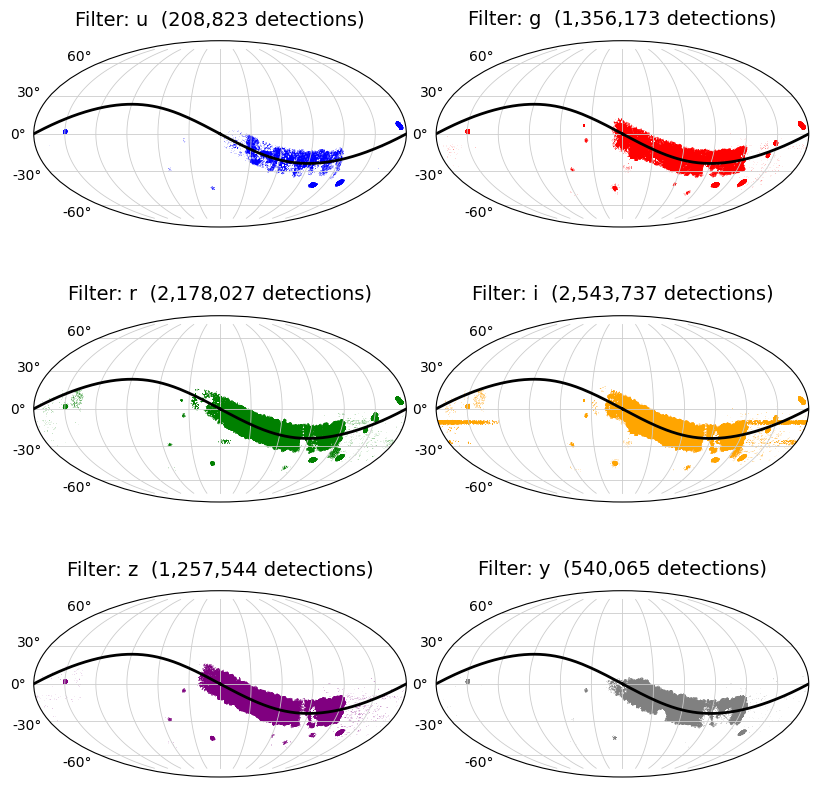

In [ ]:
filters = ['u', 'g', 'r', 'i', 'z', 'y']
# One color per band (change them here)
colors = {'u': 'blue', 'g': 'red', 'r': 'green', 'i': 'orange', 'z': 'purple', 'y': 'gray'}

(ecl_ra, ecl_dec), _ = ecl_gal()
ecl_x, ecl_y = split_mollweide(ecl_ra, ecl_dec)

fig, axes = plt.subplots(3, 2, figsize=(10, 10), subplot_kw={'projection': 'mollweide'})
for ax, f in zip(axes.flat, filters):
    d = obs[obs['filter'] == f]
    ax.scatter(f2m(d['ra'].to_numpy()) * DEG, d['dec'].to_numpy() * DEG, color=colors[f], s=0.05,
               alpha=0.5, linewidths=0, rasterized=True)
    ax.plot(ecl_x, ecl_y, color='black', lw=2)
    ax.set_title(f'Filter: {f}  ({len(d):,} detections)', fontsize=14, pad=12)
    ax.set_xticklabels([])
    ax.set_yticks(np.radians([-60, -30, 0, 30, 60]))
    ax.grid(True, color='0.8', lw=0.6)

fig.subplots_adjust(hspace=0.25, wspace=0.08)
fig.savefig('figures/sky_distribution_by_band.png', dpi=200, bbox_inches='tight')
plt.show()